# Visualization: Carotid Ultrasound Images

**A representative sample from the *Carotid Ultrasound Images* dataset: the original ultrasound image (black-and-white), the created segmentation mask (the carotid artery area outlined in white), and their overlay (green overlay).**
**A first visual inspection of data quality and annotation consistency will be performed.**


 Images found: 1100
 Masks found:   1100
 Valid pairs: True

 Example of an image: 202201121748100022VAS_slice_1069.png
 Example of a mask:   202201121748100022VAS_slice_1069.png


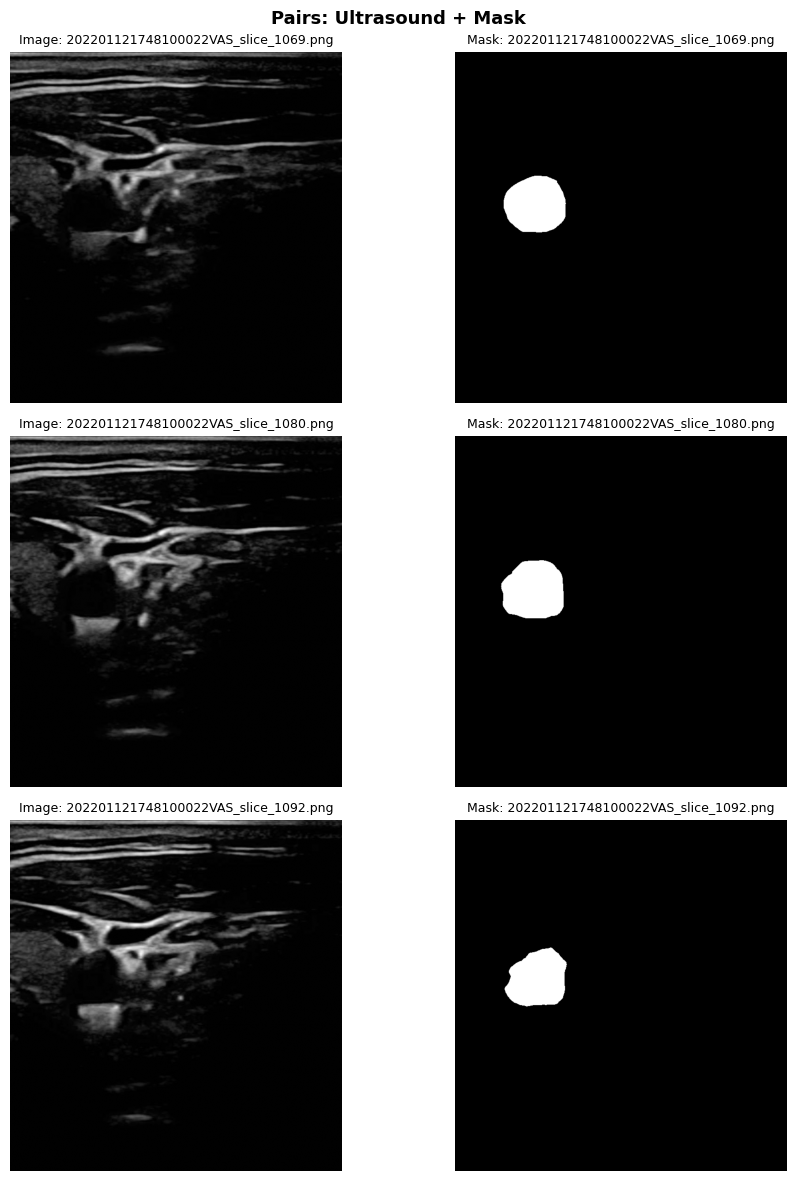

In [7]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import pandas as pd


IMAGES_PATH = "/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/US images"
MASKS_PATH  = "/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images"
CARDIO_PATH = "/kaggle/input/datasets/sulianova/cardiovascular-disease-dataset/cardio_train.csv"


images_list = sorted(os.listdir(IMAGES_PATH))
masks_list  = sorted(os.listdir(MASKS_PATH))

print(f" Images found: {len(images_list)}")
print(f" Masks found:  {len(masks_list)}")
print(f" Valid pairs: {len(images_list) == len(masks_list)}")
print(f"\n Example of an image: {images_list[0]}")
print(f" Example of a mask:   {masks_list[0]}")


fig, axes = plt.subplots(3, 2, figsize=(10, 12))
for i in range(3):
    img  = np.array(Image.open(os.path.join(IMAGES_PATH, images_list[i])).convert('L'))
    mask = np.array(Image.open(os.path.join(MASKS_PATH,  masks_list[i])).convert('L'))

    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].set_title(f'Image: {images_list[i]}', fontsize=9)
    axes[i, 0].axis('off')

    axes[i, 1].imshow(mask, cmap='gray')
    axes[i, 1].set_title(f'Mask: {masks_list[i]}', fontsize=9)
    axes[i, 1].axis('off')

plt.suptitle('Pairs: Ultrasound + Mask', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('first_look.png', dpi=150, bbox_inches='tight')
plt.show()

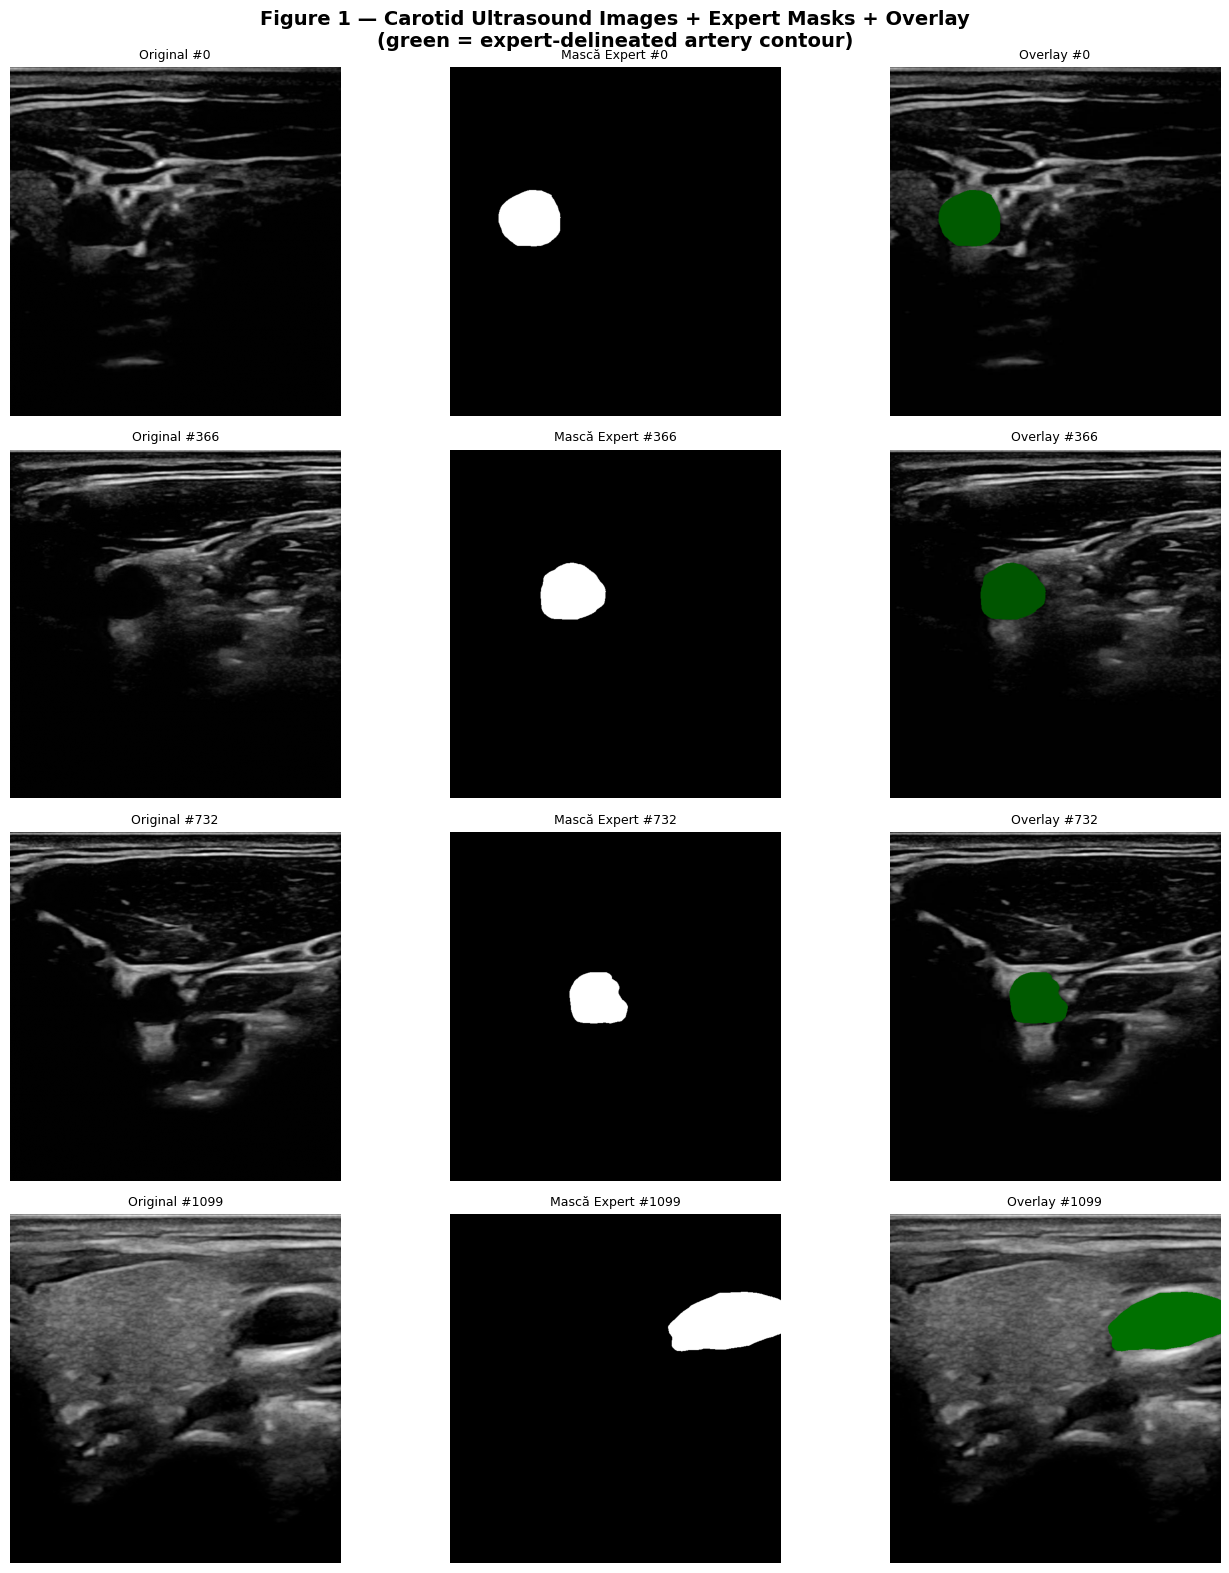

In [2]:
fig, axes = plt.subplots(4, 3, figsize=(14, 16))
fig.suptitle('Figure 1 — Carotid Ultrasound Images + Expert Masks + Overlay\n'
             '(green = expert-delineated artery contour)', fontsize=14, fontweight='bold')

indices = np.linspace(0, len(images_list)-1, 4, dtype=int)

for row, idx in enumerate(indices):
    img  = np.array(Image.open(os.path.join(IMAGES_PATH, images_list[idx])).convert('L'))
    mask = np.array(Image.open(os.path.join(MASKS_PATH,  masks_list[idx])).convert('L'))

    # Overlay: imagine originală + mască în verde semitransparent
    img_rgb       = np.stack([img, img, img], axis=-1)
    overlay       = img_rgb.copy()
    mask_bool     = mask > 127
    overlay[mask_bool, 0] = 0
    overlay[mask_bool, 1] = min(255, img[mask_bool].mean().astype(int) + 80)
    overlay[mask_bool, 2] = 0

    axes[row, 0].imshow(img, cmap='gray')
    axes[row, 0].set_title(f'Original #{idx}', fontsize=9)
    axes[row, 0].axis('off')

    axes[row, 1].imshow(mask, cmap='gray')
    axes[row, 1].set_title(f'Mască Expert #{idx}', fontsize=9)
    axes[row, 1].axis('off')

    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title(f'Overlay #{idx}', fontsize=9)
    axes[row, 2].axis('off')

plt.tight_layout()
plt.savefig('figure1_mosaic.png', dpi=150, bbox_inches='tight')
plt.show()


   Image dimentions:
   Width  — min: 709, max: 709, medie: 709 px
   Height — min: 749, max: 749, medie: 749 px
   Aspect ratio — min: 0.95, max: 0.95


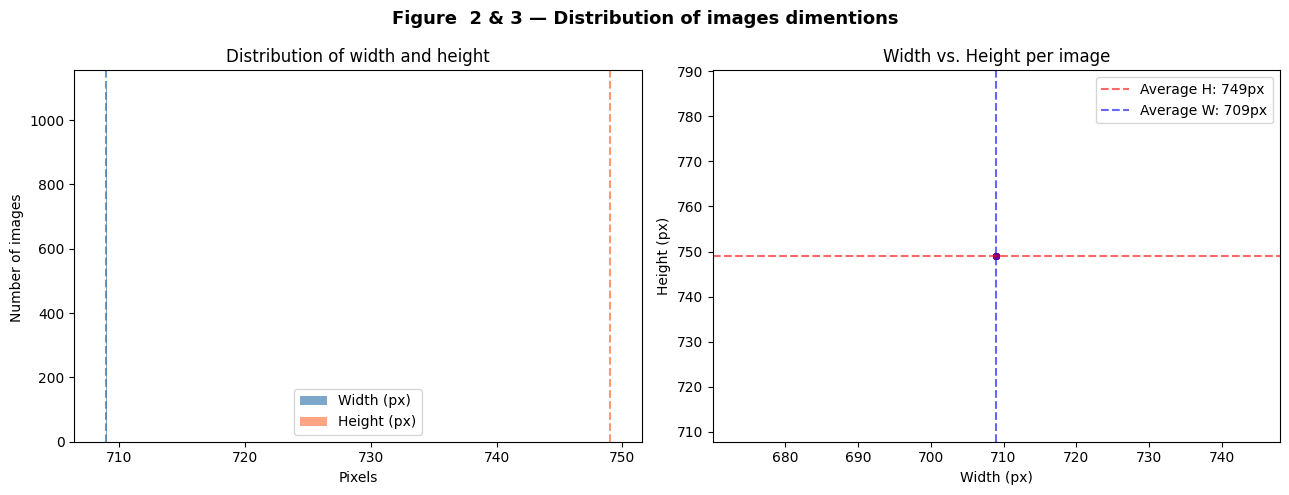

In [8]:
# Collect dimentions of the images - 
widths, heights, aspect_ratios = [], [], []

for fname in images_list:
    img = Image.open(os.path.join(IMAGES_PATH, fname))
    w, h = img.size
    widths.append(w)
    heights.append(h)
    aspect_ratios.append(w / h)

print(f"   Image dimentions:")
print(f"   Width  — min: {min(widths)}, max: {max(widths)}, medie: {np.mean(widths):.0f} px")
print(f"   Height — min: {min(heights)}, max: {max(heights)}, medie: {np.mean(heights):.0f} px")
print(f"   Aspect ratio — min: {min(aspect_ratios):.2f}, max: {max(aspect_ratios):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Figure  2 & 3 — Distribution of images dimentions', fontsize=13, fontweight='bold')

# Figure 2 — Histogram of Widths and Heights
axes[0].hist(widths,  bins=20, alpha=0.7, color='steelblue', label='Width (px)')
axes[0].hist(heights, bins=20, alpha=0.7, color='coral',     label='Height (px)')
axes[0].set_xlabel('Pixels')
axes[0].set_ylabel('Number of images ')
axes[0].set_title('Distribution of width and height')
axes[0].legend()
axes[0].axvline(np.mean(widths),  color='steelblue', linestyle='--', alpha=0.8, label=f'Medie lățime: {np.mean(widths):.0f}px')
axes[0].axvline(np.mean(heights), color='coral',     linestyle='--', alpha=0.8)

# Figure 3 — Scatter Plot: Width vs Height
axes[1].scatter(widths, heights, alpha=0.5, color='purple', s=15)
axes[1].set_xlabel('Width (px)')
axes[1].set_ylabel('Height (px)')
axes[1].set_title('Width vs. Height per image')
axes[1].axhline(np.mean(heights), color='red', linestyle='--', alpha=0.6, label=f'Average H: {np.mean(heights):.0f}px')
axes[1].axvline(np.mean(widths),  color='blue', linestyle='--', alpha=0.6, label=f'Average W: {np.mean(widths):.0f}px')
axes[1].legend()

plt.tight_layout()
plt.savefig('figure2_3_dimentions.png', dpi=150, bbox_inches='tight')
plt.show()


**All images have the same dimentions: 709×749 px (aspect ratio ~0.95) which eliminates the need for a variable resizing step and simplifies the preprocessing pipeline.**

# Distribution of Mask Coverage (% Artery Pixels)

📊 Mask Coverage(% pixels = artery):
   Average  : 2.35%
   Min  : 1.31%
   Max  : 5.37%
   Std Dev: 0.51%


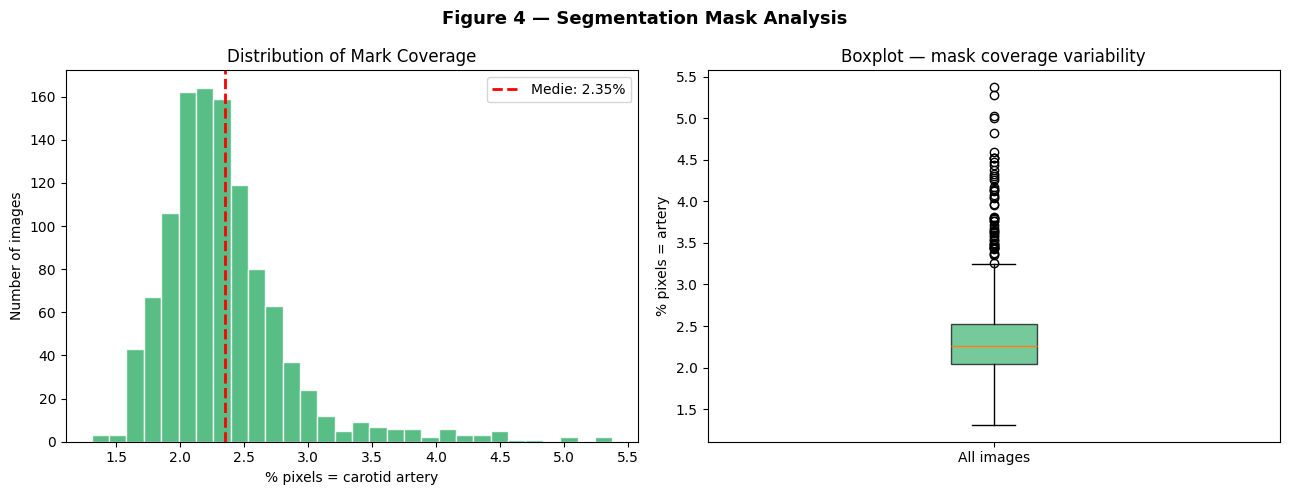

In [9]:
mask_coverage = []  # Percentage of Pixels = Artery

for fname in masks_list:
    mask = np.array(Image.open(os.path.join(MASKS_PATH, fname)).convert('L'))
    total_pixels  = mask.size
    artery_pixels = (mask > 127).sum()
    mask_coverage.append((artery_pixels / total_pixels) * 100)

print(f"📊 Mask Coverage(% pixels = artery):")
print(f"   Average  : {np.mean(mask_coverage):.2f}%")
print(f"   Min  : {np.min(mask_coverage):.2f}%")
print(f"   Max  : {np.max(mask_coverage):.2f}%")
print(f"   Std Dev: {np.std(mask_coverage):.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Figure 4 — Segmentation Mask Analysis', fontsize=13, fontweight='bold')

axes[0].hist(mask_coverage, bins=30, color='mediumseagreen', edgecolor='white', alpha=0.85)
axes[0].axvline(np.mean(mask_coverage), color='red', linestyle='--', linewidth=2,
                label=f'Medie: {np.mean(mask_coverage):.2f}%')
axes[0].set_xlabel('% pixels = carotid artery')
axes[0].set_ylabel('Number of images')
axes[0].set_title('Distribution of Mark Coverage')
axes[0].legend()

axes[1].boxplot(mask_coverage, patch_artist=True,
                boxprops=dict(facecolor='mediumseagreen', alpha=0.7))
axes[1].set_ylabel('% pixels = artery')
axes[1].set_title('Boxplot — mask coverage variability')
axes[1].set_xticks([1])
axes[1].set_xticklabels(['All images'])

plt.tight_layout()
plt.savefig('figure4_masks.png', dpi=150, bbox_inches='tight')
plt.show()


### Interpretation

The carotid artery occupies on average only **~2.35% of the image area** (min: 1.31%, max: 5.37%, std: 0.51%). This severe class imbalance (~98% background vs ~2% artery) has direct implications for model training:

- **Dice Loss or Focal Loss** are preferred over standard Binary Cross-Entropy, which would effectively ignore the minority class.
- Without class weighting or targeted data augmentation, the model will be biased toward predicting background.
- The relatively narrow distribution (low std) suggests consistent artery size across patients—no extreme cases of highly dilated arteries.

# Exploratory Analysis of Cardiovascular Clinical Data

Dataset: 69649 patients, 15 collumns
       age_years     ap_hi     ap_lo       bmi  cholesterol
count   69649.00  69649.00  69649.00  69649.00     69649.00
mean       52.85    127.09     96.65     27.56         1.37
std         6.76     16.99    188.70      6.08         0.68
min        29.00     85.00      0.00      3.47         1.00
25%        48.00    120.00     80.00     23.88         1.00
50%        53.00    120.00     80.00     26.40         1.00
75%        58.00    140.00     90.00     30.25         2.00
max        64.00    240.00  11000.00    298.67         3.00


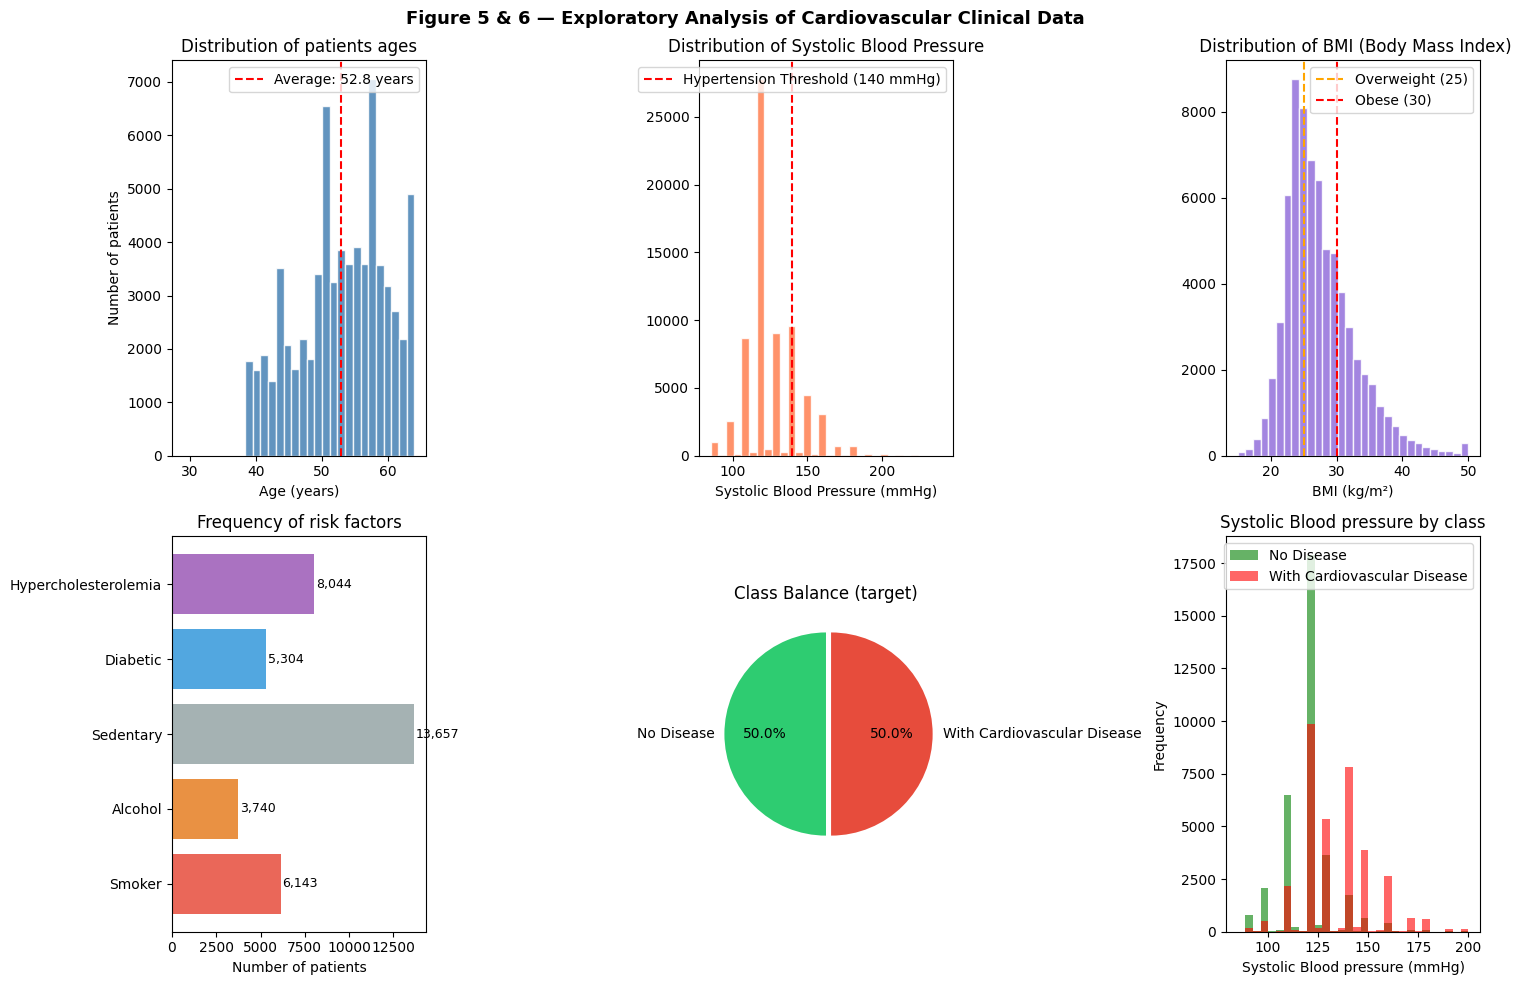

In [12]:
df = pd.read_csv(CARDIO_PATH, sep=';')

# Quick Cleanup for EDA
df['age_years'] = (df['age'] / 365).astype(int)
df['bmi']       = df['weight'] / ((df['height'] / 100) ** 2)
df              = df[(df['ap_hi'] > 80) & (df['ap_hi'] < 250)]   # excluding outliers

print(f"Dataset: {df.shape[0]} patients, {df.shape[1]} collumns")
print(df[['age_years', 'ap_hi', 'ap_lo', 'bmi', 'cholesterol']].describe().round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Figure 5 & 6 — Exploratory Analysis of Cardiovascular Clinical Data', fontsize=13, fontweight='bold')

# Distribution of patients ages
axes[0,0].hist(df['age_years'], bins=30, color='steelblue', edgecolor='white', alpha=0.85)
axes[0,0].set_title('Distribution of patients ages')
axes[0,0].set_xlabel('Age (years)')
axes[0,0].set_ylabel('Number of patients')
axes[0,0].axvline(df['age_years'].mean(), color='red', linestyle='--',
                   label=f"Average: {df['age_years'].mean():.1f} years")
axes[0,0].legend()

# Distribution of Blood Pressure
axes[0,1].hist(df['ap_hi'], bins=30, color='coral', edgecolor='white', alpha=0.85)
axes[0,1].set_title('Distribution of Systolic Blood Pressure')
axes[0,1].set_xlabel('Systolic Blood Pressure (mmHg)')
axes[0,1].axvline(140, color='red', linestyle='--', label='Hypertension Threshold (140 mmHg)')
axes[0,1].legend()

#  Distribution of BMI (Body Mass Index)
axes[0,2].hist(df['bmi'].clip(15, 50), bins=30, color='mediumpurple', edgecolor='white', alpha=0.85)
axes[0,2].set_title(' Distribution of BMI (Body Mass Index)')
axes[0,2].set_xlabel('BMI (kg/m²)')
axes[0,2].axvline(25, color='orange', linestyle='--', label='Overweight (25)')
axes[0,2].axvline(30, color='red',    linestyle='--', label='Obese (30)')
axes[0,2].legend()

# Risk factors - barplot
risk_factors = {
    'Smoker': df['smoke'].sum(),
    'Alcohol': df['alco'].sum(),
    'Sedentary': (df['active'] == 0).sum(),
    'Diabetic': (df['gluc'] == 3).sum(),
    'Hypercholesterolemia': (df['cholesterol'] == 3).sum(),
}
axes[1,0].barh(list(risk_factors.keys()), list(risk_factors.values()),
               color=['#e74c3c','#e67e22','#95a5a6','#3498db','#9b59b6'], alpha=0.85)
axes[1,0].set_title('Frequency of risk factors')
axes[1,0].set_xlabel('Number of patients')
for i, v in enumerate(risk_factors.values()):
    axes[1,0].text(v + 100, i, f'{v:,}', va='center', fontsize=9)

# Distribution of Target Class
class_counts = df['cardio'].value_counts()
axes[1,1].pie(class_counts, labels = ['No Disease', 'With Cardiovascular Disease'],
              autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'],
              startangle=90, explode=[0, 0.05])
axes[1, 1].set_title('Class Balance (target)')

# Systolic Blood pressure by class
df[df['cardio']==0]['ap_hi'].clip(80, 200).plot(kind='hist', bins=30, alpha=0.6,
    color='green', label='No Disease', ax=axes[1,2])
df[df['cardio']==1]['ap_hi'].clip(80, 200).plot(kind='hist', bins=30, alpha=0.6,
    color='red',   label='With Cardiovascular Disease',   ax=axes[1,2])
axes[1,2].set_title('Systolic Blood pressure by class')
axes[1,2].set_xlabel('Systolic Blood pressure (mmHg)')
axes[1,2].legend()

plt.tight_layout()
plt.savefig('Figure5_6_clinics.png', dpi=150, bbox_inches='tight')
plt.show()


### Interpretation

**Age:** The distribution is concentrated between **48–58 years** (mean ~52.85 years, range 29–64). Patients are middle-aged adults.

**Systolic Blood Pressure:** The distribution is centered around ~120–140 mmHg. The clinical hypertension threshold (**140 mmHg**) is exceeded by a significant portion of patients—hypertension is a major risk factor for carotid atherosclerosis.

**BMI:** Values are distributed in the 15–50 kg/m² range, with a mean of ~27.56 (**overweight** category). Presence of extreme outliers.

**Diastolic Blood Pressure (aplo):** Severe outliers exist (max=11000 mmHg) that were filtered out by the previously applied `aphi > 80` condition. This confirms the importance of cleaning raw clinical data.

**Cholesterol:** Discrete values (1, 2, 3) indicate that the variable is **categorized** (normal/elevated/very high), not continuous.

**Overall Conclusion:** The clinical data present a typical profile for a cardiovascular patient: middle-aged, blood pressure at the hypertension threshold, mild overweight.